# Практическая работа №5
## Классификатор и анализ метрик

**Вариант B**

**Датасет:** Titanic

**Цель:** построить модель бинарной классификации, исследовать ROC-кривую, PR-кривую, матрицу ошибок и выбрать порог классификации с учётом стоимости ошибок.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

In [2]:
df = pd.read_csv("../data/titanic.csv")

display(df.head())

print("Размер таблицы:", df.shape)
print("\nБаланс классов:")
print(df["Survived"].value_counts(normalize=True).round(3))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Размер таблицы: (891, 12)

Баланс классов:
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [3]:
numeric_features = ["Age", "Fare", "SibSp", "Parch"]
categorical_features = ["Sex", "Pclass", "Embarked"]

X = df[numeric_features + categorical_features]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (712, 7)
Test: (179, 7)


### Разделение данных

Данные разделены на обучающую (80%) и тестовую (20%) выборки.

Используется стратификация, чтобы сохранить примерно одинаковое соотношение выживших и погибших в обеих выборках.

Тестовые данные не используются при обучении модели и выборе параметров предобработки.

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Модель успешно обучена!")

Модель успешно обучена!


In [5]:
y_proba = model.predict_proba(X_test)[:, 1]

print("Первые 10 вероятностей:")
print(np.round(y_proba[:10], 3))

Первые 10 вероятностей:
[0.068 0.048 0.158 0.036 0.672 0.439 0.766 0.305 0.345 0.175]


### Вероятности классификации

Модель LogisticRegression возвращает вероятность принадлежности пассажира к классу 1 (выжил).

При пороге 0,5 пассажир относится к классу 1, если предсказанная вероятность не меньше 50%.

Изменение порога влияет на количество ложноположительных и ложноотрицательных предсказаний.

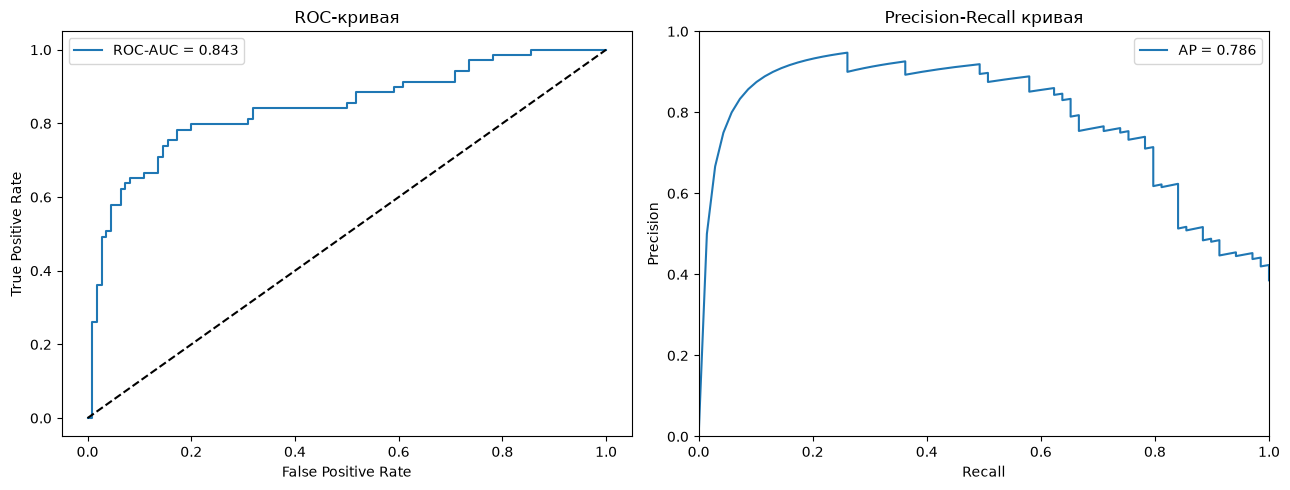

In [6]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
precision, recall, _ = precision_recall_curve(y_test, y_proba)

roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_title("ROC-кривая")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

axes[1].plot(recall, precision, label=f"AP = {pr_auc:.3f}")
axes[1].set_title("Precision-Recall кривая")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()

### Анализ ROC и PR-кривых

ROC-кривая показывает качество разделения двух классов при разных порогах классификации.

ROC-AUC, близкий к 1, означает хорошую способность модели различать выживших и погибших. Значение около 0,5 соответствует случайному ранжированию.

PR-кривая показывает компромисс между Precision и Recall. Она особенно полезна при неравномерном распределении классов.

Average Precision (AP) обобщает качество по PR-кривой. Чем выше AP, тем лучше модель ранжирует положительные примеры по точности и полноте.

In [7]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

model.fit(X_fit, y_fit)

val_proba = model.predict_proba(X_val)[:, 1]

cost_fp = 1
cost_fn = 3

thresholds = np.arange(0.10, 0.91, 0.01)
costs = []

for threshold in thresholds:
    val_pred = (val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=[0, 1]
    ).ravel()

    total_cost = cost_fp * fp + cost_fn * fn
    costs.append(total_cost)

best_threshold = float(thresholds[np.argmin(costs)])

print("Выбранный порог:", round(best_threshold, 2))
print("Минимальная стоимость ошибок:", min(costs))

Выбранный порог: 0.33
Минимальная стоимость ошибок: 58


In [8]:
model.fit(X_train, y_train)

y_proba = model.predict_proba(X_test)[:, 1]

def evaluate_threshold(threshold):
    y_pred = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "FP": fp,
        "FN": fn,
        "Cost": cost_fp * fp + cost_fn * fn
    }

results = pd.DataFrame([
    evaluate_threshold(0.5),
    evaluate_threshold(best_threshold)
])

display(results.round(3))

,Threshold,Accuracy,Precision,Recall,F1,FP,FN,Cost
0,0.50,0.804,0.793,0.667,0.724,12,23,81
1,0.33,0.782,0.688,0.797,0.738,25,14,67


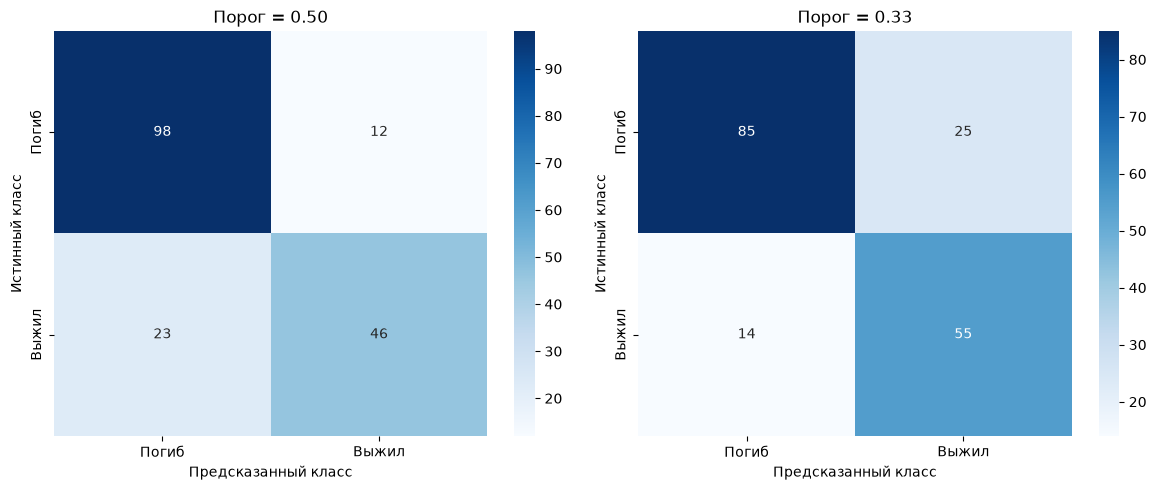

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, threshold in zip(axes, [0.5, best_threshold]):
    y_pred = (y_proba >= threshold).astype(int)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Погиб", "Выжил"],
        yticklabels=["Погиб", "Выжил"],
        ax=ax
    )

    ax.set_title(f"Порог = {threshold:.2f}")
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")

plt.tight_layout()
plt.show()

## Итоговый отчёт

1. В работе обучена модель LogisticRegression для предсказания выживания пассажиров Titanic.

2. Для подготовки данных использован Pipeline: числовые пропуски заполнены медианой, числовые признаки масштабированы, категориальные признаки закодированы с помощью OneHotEncoder.

3. Построены ROC и PR-кривые. ROC-AUC отражает способность модели различать классы, а Average Precision показывает качество ранжирования положительных примеров.

4. В учебной постановке цена ложноотрицательной ошибки FN принята в 3 раза выше цены ложноположительной ошибки FP. Поэтому особое внимание уделяется Recall и общей стоимости ошибок.

5. Проведено сравнение порога 0,5 с порогом, подобранным на валидационной выборке.

6. Рассчитаны Accuracy, Precision, Recall и F1, построены матрицы ошибок.

7. Итоговый порог выбирается на основе стоимости ошибок и метрик. Тестовая выборка используется только для окончательной оценки, а не для подбора порога.

**Вывод:** изменение порога позволяет управлять балансом между пропуском положительных примеров и ложными срабатываниями. Конкретный результат следует оценивать по полученным метрикам и стоимости ошибок.